## EDA

In [1]:
import os
import psycopg
import dotenv
import pandas as pd

connection = {"sslmode": "require", "target_session_attrs": "read-write"}
dotenv.load_dotenv()
postgres_credentials = {
    "host": os.getenv("DB_DESTINATION_HOST"),
    "port": os.getenv("DB_DESTINATION_PORT"),
    "dbname": os.getenv("DB_DESTINATION_NAME"),
    "user": os.getenv("DB_DESTINATION_USER"),
    "password": os.getenv("DB_DESTINATION_PASSWORD"),
}
assert all([var_value != "" for var_value in list(postgres_credentials.values())])

connection.update(postgres_credentials)
TABLE_NAME = "flats_price"


with psycopg.connect(**connection) as conn:
    with conn.cursor() as cur:
        cur.execute(f"SELECT * FROM {TABLE_NAME}")
        data = cur.fetchall()
        columns = [col[0] for col in cur.description]


df = pd.DataFrame(data, columns=columns)

Ознакомление с данными

In [2]:
df.head()

,id,building_id,floor,kitchen_area,living_area,rooms,is_apartment,studio,total_area,price,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator
0,0,6220,9,9.9,19.900000,1,False,False,35.099998,9500000.0,1965,6,55.717113,37.781120,2.64,84,12,True
1,1,18012,7,0.0,16.600000,1,False,False,43.000000,13500000.0,2001,2,55.794849,37.608013,3.00,97,10,True
2,2,17821,9,9.0,32.000000,2,False,False,56.000000,13500000.0,2000,4,55.740040,37.761742,2.70,80,10,True
3,3,18579,1,10.1,43.099998,3,False,False,76.000000,20000000.0,2002,4,55.672016,37.570877,2.64,771,17,True
4,4,9293,3,3.0,14.000000,1,False,False,24.000000,5200000.0,1971,1,55.808807,37.707306,2.60,208,9,True


In [3]:
df.shape

(141362, 18)

In [4]:
df.dtypes

id                     int64
building_id            int64
floor                  int64
kitchen_area         float64
living_area          float64
rooms                  int64
is_apartment            bool
studio                  bool
total_area           float64
price                float64
build_year             int64
building_type_int      int64
latitude             float64
longitude            float64
ceiling_height       float64
flats_count            int64
floors_total           int64
has_elevator            bool
dtype: object

Стоит учесть, что building_type_int это категориальный признак.

In [5]:
df["building_type_int"].value_counts().sort_index()

building_type_int
0     1927
1    23164
2    25265
3     1773
4    78696
5        4
6    10533
Name: count, dtype: int64

In [6]:
df.isna().sum()

id                   0
building_id          0
floor                0
kitchen_area         0
living_area          0
rooms                0
is_apartment         0
studio               0
total_area           0
price                0
build_year           0
building_type_int    0
latitude             0
longitude            0
ceiling_height       0
flats_count          0
floors_total         0
has_elevator         0
dtype: int64

Пропущенные значения в данных отсутствуют.

In [7]:
df.describe()

,id,building_id,floor,kitchen_area,living_area,rooms,total_area,price,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total
count,141362.000000,141362.000000,141362.000000,141362.000000,141362.000000,141362.000000,141362.000000,1.413620e+05,141362.000000,141362.000000,141362.000000,141362.000000,141362.000000,141362.000000,141362.000000
mean,70680.500000,14053.665235,7.467346,9.001579,31.056948,2.129476,62.374644,1.944162e+07,1986.600048,3.232941,55.730059,37.589235,2.753650,251.993230,14.107554
std,40807.838714,6988.831066,5.717144,5.264076,23.968640,0.994340,40.295864,6.626954e+07,22.136409,1.459461,0.102611,0.150122,0.223275,207.336169,6.898045
min,0.000000,1.000000,1.000000,0.000000,0.000000,1.000000,11.000000,1.100000e+01,1901.000000,0.000000,55.211460,36.864372,2.000000,1.000000,1.000000
25%,35340.250000,8535.250000,3.000000,6.100000,19.000000,1.000000,39.299999,8.900000e+06,1969.000000,2.000000,55.653858,37.491764,2.640000,111.000000,9.000000
50%,70680.500000,14332.000000,6.000000,8.800000,29.400000,2.000000,53.000000,1.185000e+07,1985.000000,4.000000,55.724686,37.581146,2.640000,200.000000,14.000000
75%,106020.750000,20475.000000,10.000000,10.200000,41.400002,3.000000,72.000000,1.695000e+07,2007.000000,4.000000,55.807323,37.691055,2.800000,324.000000,17.000000
max,141361.000000,24620.000000,56.000000,203.000000,700.000000,20.000000,960.299988,9.873738e+09,2023.000000,6.000000,56.011032,37.946411,27.000000,4455.000000,99.000000


У целевой переменной price max значительнее превышает мединану. Также максимальная высота потолка  равная 27 метрам выглядит как ошибка в данных.

In [8]:
df[df["ceiling_height"] > 5]["ceiling_height"].value_counts().sort_index()

ceiling_height
5.2      1
6.0     17
7.0      4
8.0      6
27.0     1
Name: count, dtype: int64

In [9]:
df[df["ceiling_height"] == 27]

,id,building_id,floor,kitchen_area,living_area,rooms,is_apartment,studio,total_area,price,build_year,building_type_int,latitude,longitude,ceiling_height,flats_count,floors_total,has_elevator
83673,83673,3852,1,6.0,18.799999,1,False,False,31.700001,9000000.0,1961,1,55.867657,37.669575,27.0,60,5,False


Ошибка в данных, однокомнатная квартира площадью 31.7 м^2 и высотой потолка 27 метров выглядит нереалистично.

Непрерывные числовые признаки

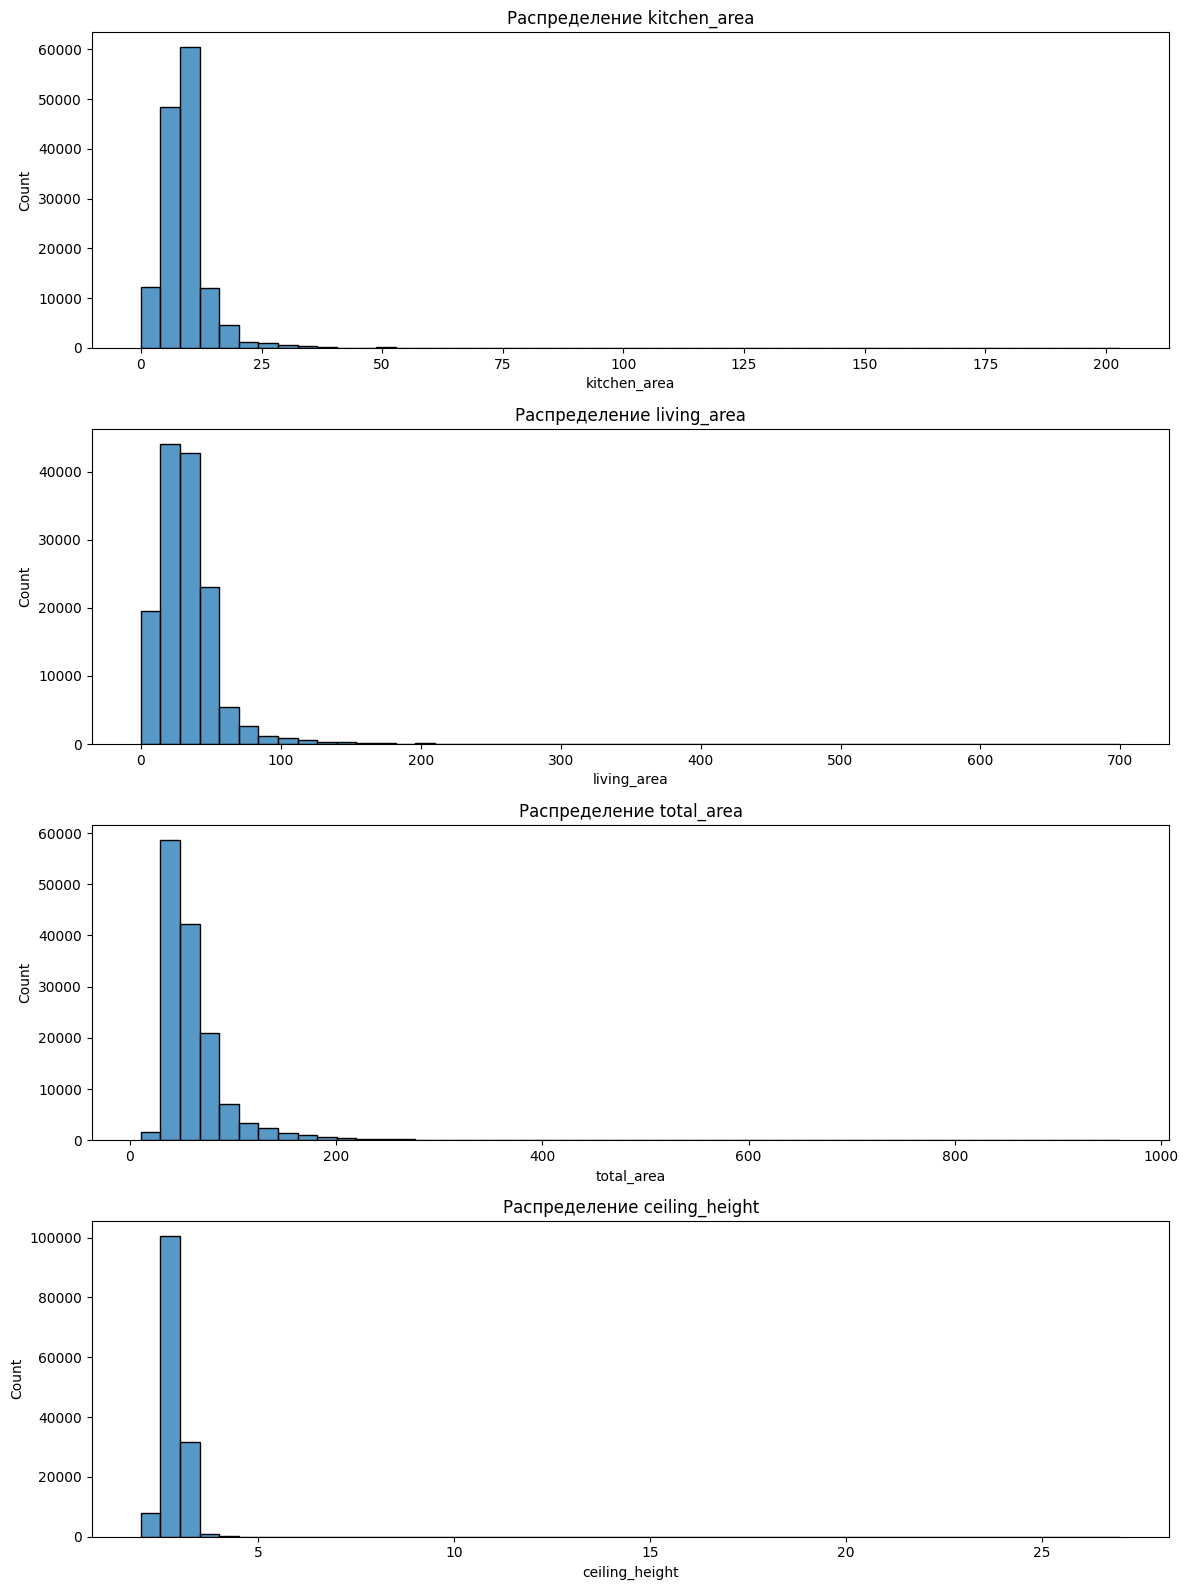

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

cols = [
    "kitchen_area",
    "living_area",
    "total_area",
    "ceiling_height",
]

fig, axes = plt.subplots(len(cols), 1, figsize=(12, 16))

for i, col in enumerate(cols):
    sns.histplot(data=df, x=col, bins=50, ax=axes[i],)
    axes[i].set_title(f"Распределение {col}")

plt.tight_layout()
plt.savefig("assets/numeric_features_distribution.png",)

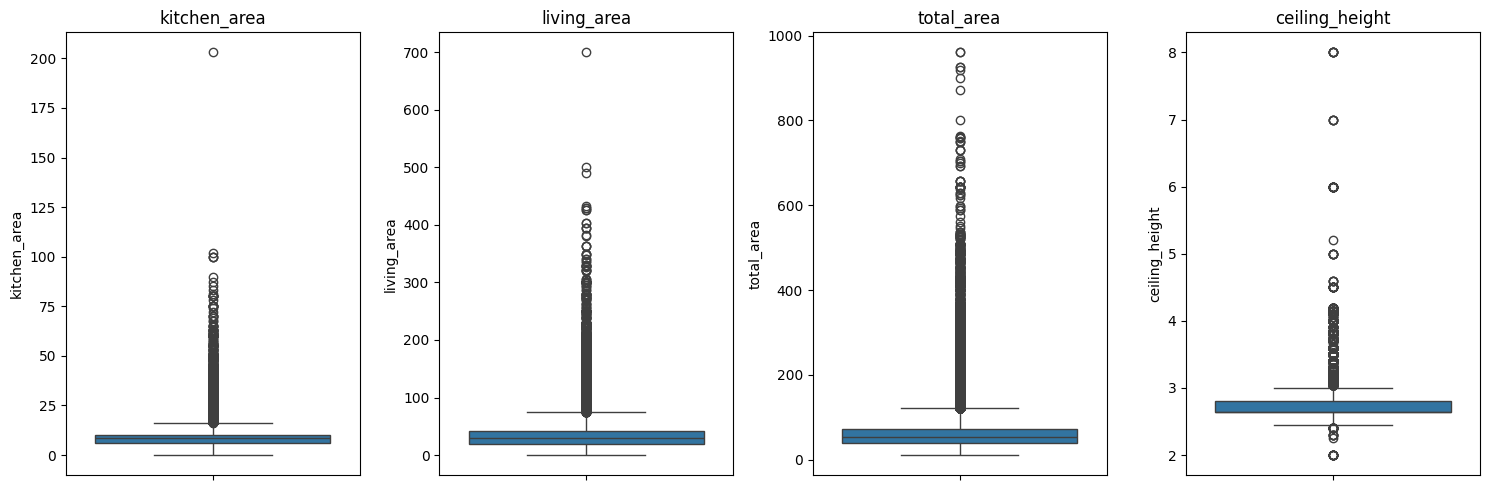

<Figure size 640x480 with 0 Axes>

In [11]:
area_cols = ["kitchen_area", "living_area", "total_area", "ceiling_height"]

fig, axes = plt.subplots(1, 4, figsize=(15, 5))

for col, ax in zip(area_cols, axes):

    sns.boxplot(df[df["ceiling_height"] != 27],y=col,ax=ax,)
    ax.set_title(col)

plt.tight_layout()
plt.show()
plt.savefig("assets/numeric_features_boxplot.png")

В признаках kitchen_area, living_area, total_area и ceiling height наблюдается большое количество потенциальных выбросов и длинный правый хвост.

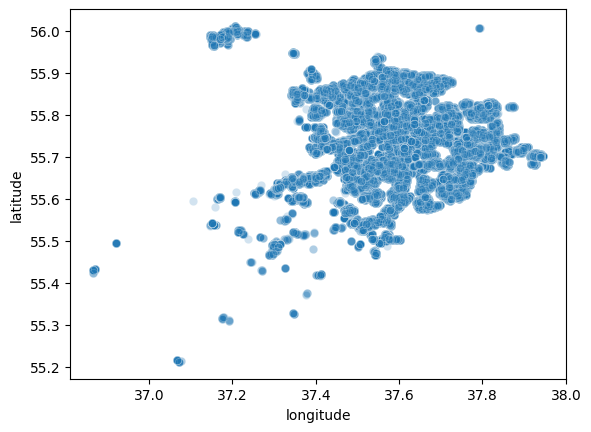

In [12]:
sns.scatterplot(
    data=df,
    x="longitude",
    y="latitude",
    alpha=0.2,
)
plt.savefig("assets/longitude*latitude.png")

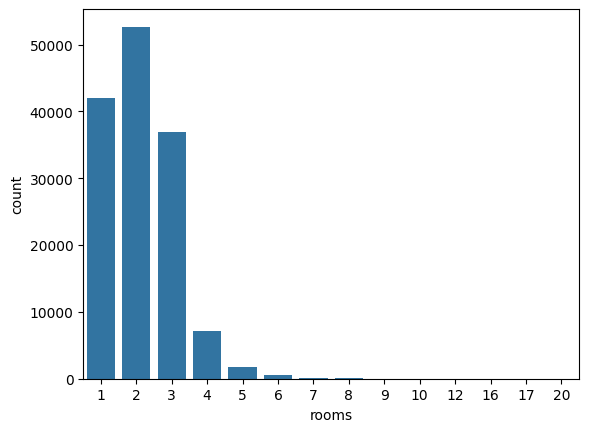

In [13]:
sns.countplot(data=df, x='rooms')
plt.savefig("assets/rooms_distribution.png")

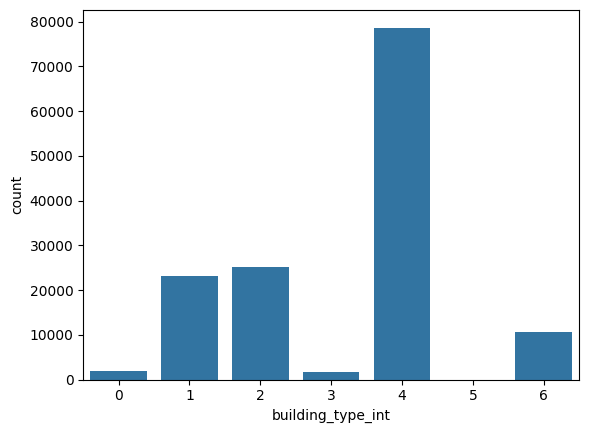

In [14]:
sns.countplot(df, x="building_type_int")
plt.savefig("assets/building_type.png")

Категории сильно несбалансированы

Бинарные признаки

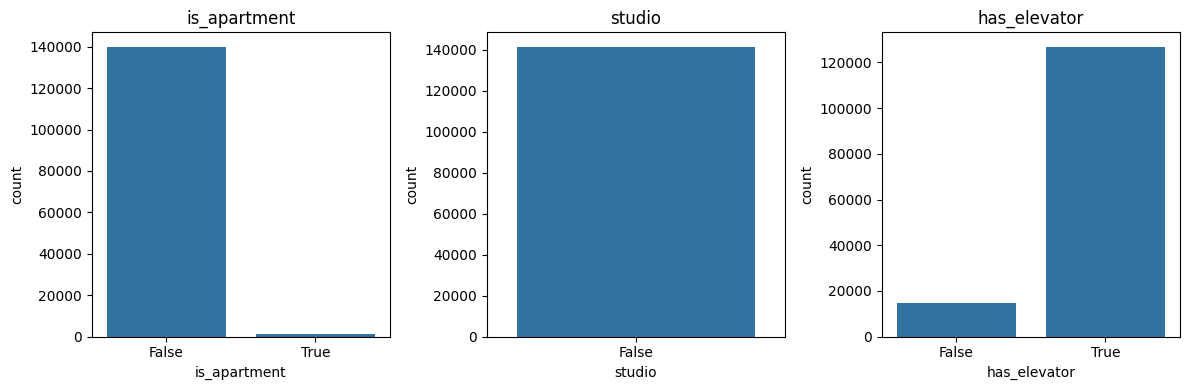

<Figure size 640x480 with 0 Axes>

In [15]:
binary_cols = ["is_apartment", "studio", "has_elevator"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for col, ax in zip(binary_cols, axes):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()
plt.savefig("assets/binary.png")

In [16]:
print(df["studio"].value_counts())
df['is_apartment'].value_counts()

studio
False    141362
Name: count, dtype: int64


is_apartment
False    139990
True       1372
Name: count, dtype: int64

Признак studio принимает только значение False

Анализ целевой переменной

In [17]:
df["price"].describe()

count    1.413620e+05
mean     1.944162e+07
std      6.626954e+07
min      1.100000e+01
25%      8.900000e+06
50%      1.185000e+07
75%      1.695000e+07
max      9.873738e+09
Name: price, dtype: float64

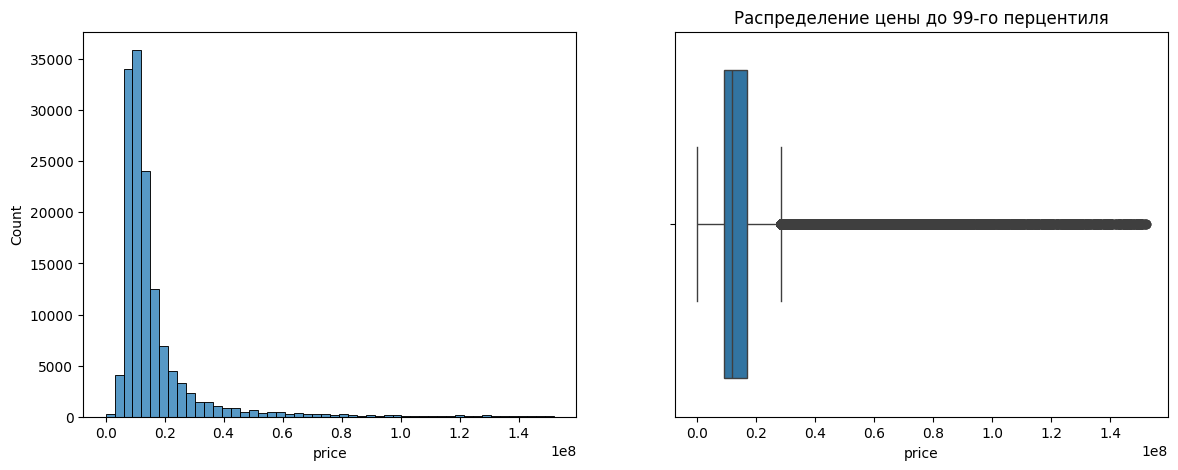

In [18]:
price_99 = df["price"].quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df[df["price"] <= price_99], x="price", bins=50, ax=axes[0])
sns.boxplot(data=df[df["price"] <= price_99], x="price", ax=axes[1])
plt.title("Распределение цены до 99-го перцентиля")
plt.savefig("assets/price_distribution.png")

# Анализ целевой переменной в зависимости от различных признаков

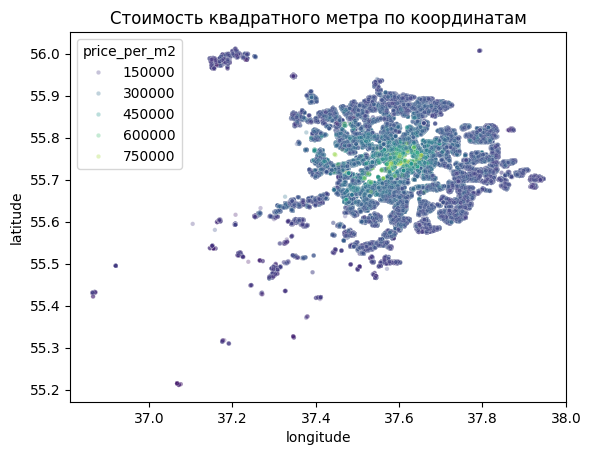

In [19]:
plot_df = df.copy()
plot_df["price_per_m2"] = plot_df["price"] / plot_df["total_area"]

price_m2_99 = plot_df["price_per_m2"].quantile(0.99)
plot_df = plot_df[plot_df["price_per_m2"] <= price_m2_99]

sns.scatterplot(data=plot_df, x="longitude", y="latitude", hue="price_per_m2", alpha=0.3, s=10, palette="viridis")

plt.title("Стоимость квадратного метра по координатам")
plt.savefig("assets/price_by_long_and_lat")

По координатам видно, что объекты в датасете расположены в Москве и ближайшем Подмосковье.

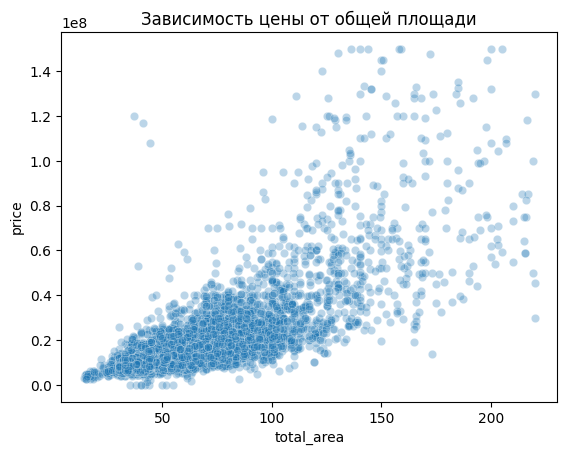

In [20]:
price_99 = df["price"].quantile(0.99)
area_99 = df["total_area"].quantile(0.99)

plot_df = df[(df["price"] <= price_99)
    & (df["total_area"] <= area_99)
]

sns.scatterplot(data=plot_df.sample(n=10_000, random_state=42),x="total_area",y="price",alpha=0.3)

plt.title("Зависимость цены от общей площади")
plt.savefig("assets/price_by_total_area.png")

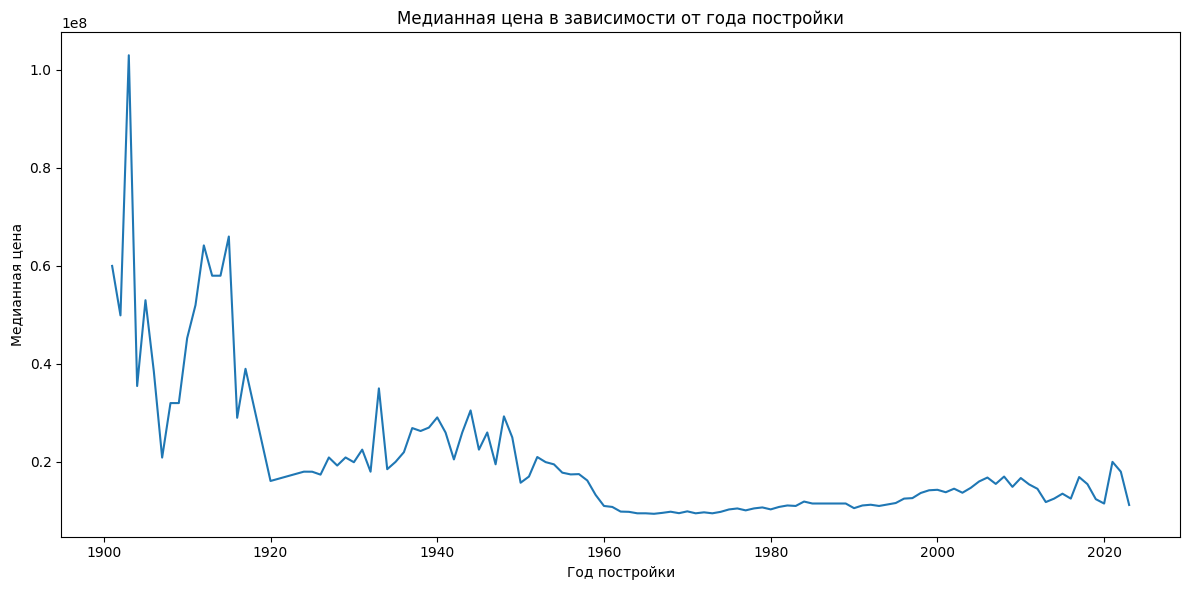

In [21]:
year_price = df.groupby("build_year", as_index=False)["price"].median()

plt.figure(figsize=(12, 6))

sns.lineplot(data=year_price, x="build_year", y="price")

plt.title("Медианная цена в зависимости от года постройки")
plt.xlabel("Год постройки")
plt.ylabel("Медианная цена")

plt.tight_layout()
plt.savefig(
    "assets/price_by_build_year.png",
)
plt.show()

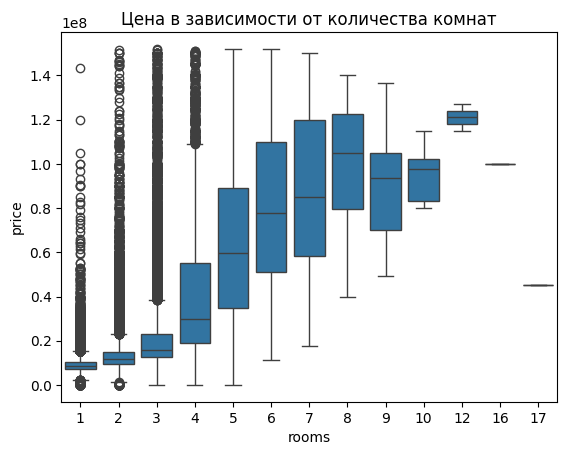

In [22]:
plot_df = df[df["price"] <= df["price"].quantile(0.99)]

sns.boxplot(data=plot_df,x="rooms",y="price")

plt.title("Цена в зависимости от количества комнат")
plt.savefig("assets/price_by_rooms.png")

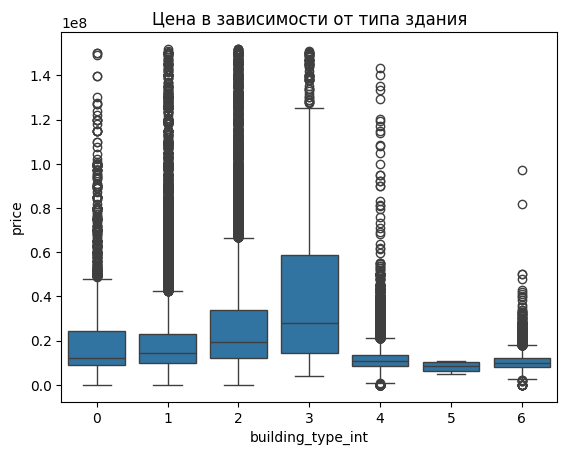

In [23]:
sns.boxplot(data=plot_df,x="building_type_int",y="price")

plt.title("Цена в зависимости от типа здания")
plt.savefig("assets/price_by_building_type.png")

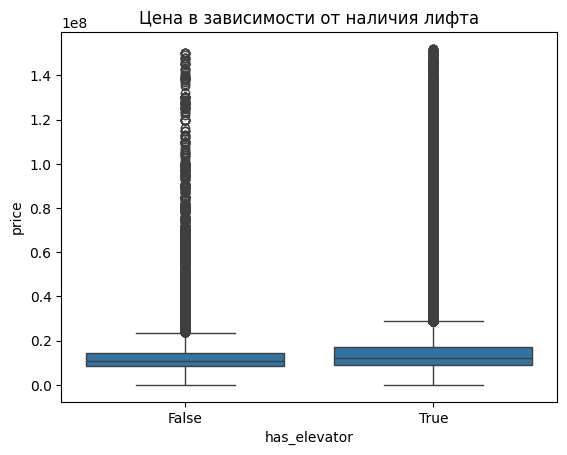

In [24]:
sns.boxplot(data=plot_df,x="has_elevator",y="price")

plt.title("Цена в зависимости от наличия лифта")
plt.savefig("assets/price_by_elevator.png")

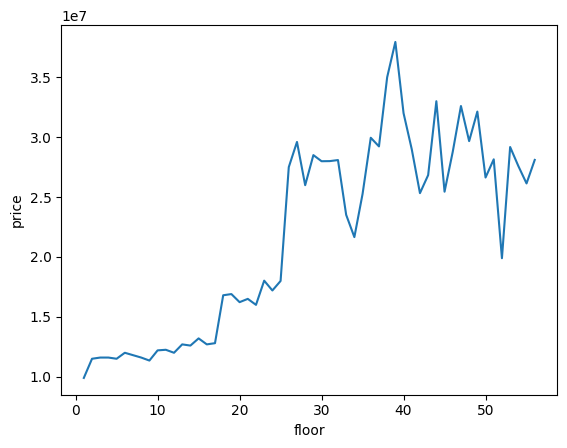

In [25]:
floor_price = (df.groupby("floor", as_index=False)["price"].median())

sns.lineplot(data=floor_price,x="floor",y="price")
plt.savefig("assets/price_by_floor.png")

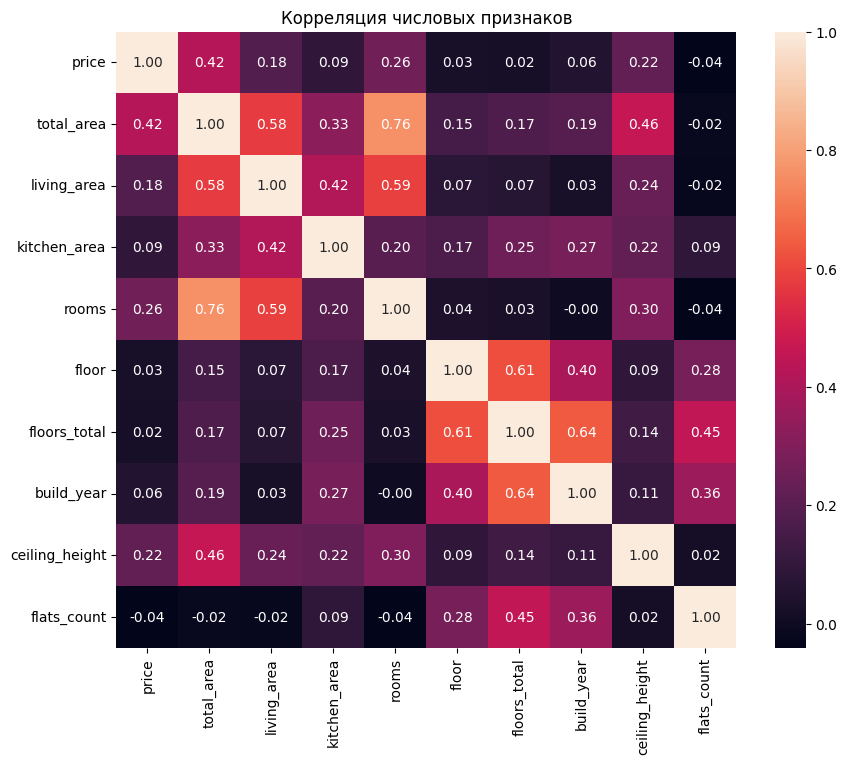

In [26]:
corr_cols = [
    "price",
    "total_area",
    "living_area",
    "kitchen_area",
    "rooms",
    "floor",
    "floors_total",
    "build_year",
    "ceiling_height",
    "flats_count",
]

corr = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr,annot=True,fmt=".2f")

plt.title("Корреляция числовых признаков")
plt.savefig("assets/correlation_matrix.png")

In [27]:
pearson = df.select_dtypes(include="number").corr(method="pearson")["price"]

spearman = df.select_dtypes(include="number").corr(method="spearman")["price"]

correlations = pd.DataFrame({"pearson": pearson,"spearman": spearman,}).sort_values("spearman", ascending=False)

correlations

,pearson,spearman
price,1.000000,1.000000
total_area,0.420681,0.764572
rooms,0.257904,0.650167
ceiling_height,0.222369,0.491822
living_area,0.180538,0.467129
kitchen_area,0.090146,0.335710
floors_total,0.023052,0.196260
build_year,0.055736,0.186221
building_id,0.064328,0.183796
floor,0.027507,0.148047


# Ключевые выводы

1) Стоимость квадратного метра имеет выраженную зависимость от расположения дома: наиболее высокие значения концентрируются в центральной части Москвы. На этапе feature engineering стоит проверить добавление признака расстояния до центра города.

2) Зависимость медианной цены от build_year различается для отдельных периодов постройки.
Поэтому стоит проверить преобразование build_year в интервалы с помощью KBinsDiscretizer.

3) Признаки kitchen_area, living_area, total_area и ceiling_height содержат большое количество экстремальных значений. Стоит попробовать RobustScaler, который устойчив к выбросам.

4) Признаки площади и количества комнат связаны между собой и могут оказывать совместное нелинейное влияние на стоимость квартиры. Поэтому стоит проверить генерацию взаимодействий между total_area, living_area, kitchen_area и rooms с помощью PolynomialFeatures.

5) Некоторые признаки сильно связаны друг с другом: rooms и total_area (0.76), floors_total и build_year (0.64), floor и floors_total (0.61).
Гипотеза: зависимости между признаками могут быть нелинейными и содержать взаимодействия, поэтому модели на основе деревьев могут подходить для данной задачи лучше простых линейных моделей. Стоит сравнить Random Forest с более сильными алгоритмами градиентного бустинга, например XGBoost.

6. Признак studio не несет никакой полезной информации для нашей модели, этот признак стоит исключить из выборки. Высота потолка 27 метров это явно ошибка в данных, следует удалить данный объект.

7) Распределение цены имеет выраженную правостороннюю асимметрию: большинство объектов находится в среднем и нижнем ценовом диапазоне, однако присутствует большое количество дорогих объектов. Такие объекты могут значительно увеличивать RMSE

In [28]:
import mlflow
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_registry_uri("http://127.0.0.1:5000")
mlflow.set_experiment("flats_price")

with mlflow.start_run(run_name="eda"):
    mlflow.log_artifacts(local_dir="assets",artifact_path="eda")
    mlflow.log_artifact("model_improvement.ipynb", artifact_path="eda")
    mlflow.log_artifact("eda_summary.md", artifact_path="eda")

## Feature Engineering

In [29]:
import os
import psycopg
import dotenv
import pandas as pd

connection = {"sslmode": "require", "target_session_attrs": "read-write"}
dotenv.load_dotenv()
postgres_credentials = {
    "host": os.getenv("DB_DESTINATION_HOST"),
    "port": os.getenv("DB_DESTINATION_PORT"),
    "dbname": os.getenv("DB_DESTINATION_NAME"),
    "user": os.getenv("DB_DESTINATION_USER"),
    "password": os.getenv("DB_DESTINATION_PASSWORD"),
}
assert all([var_value != "" for var_value in list(postgres_credentials.values())])

connection.update(postgres_credentials)
TABLE_NAME = "clean_flats_price"


with psycopg.connect(**connection) as conn:
    with conn.cursor() as cur:
        cur.execute(f"SELECT * FROM {TABLE_NAME}")
        data = cur.fetchall()
        columns = [col[0] for col in cur.description]


df = pd.DataFrame(data, columns=columns)


Разделяем на обучающую и тестовую выборку

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing  import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
import mlflow

dotenv.load_dotenv()
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_registry_uri("http://127.0.0.1:5000")

df = df[df['ceiling_height'] != 27]
X = df.drop(columns = ['price', 'building_id', 'studio'])
y = df['price']

cat_features = df.select_dtypes(['object']).columns.tolist()
cat_features.append("building_type_int")
train_size = 0.8
shuffle=True

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42, shuffle=shuffle)

Будем тестировать наши преобразования с признаками на RandomForest и XGboost. 
Базовая модель имела такие показатели 

rmse: 2795542.821311236 <br>
mae: 2007594.9329998526 <br>
r2: 0.8019331564017734

In [31]:
from xgboost import XGBRegressor

experiment_id = mlflow.get_experiment_by_name("flats_price").experiment_id

def test_RandomForest(preproc, run_name, params):
    
    model = RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_leaf=2,
                              max_features="sqrt", random_state=42, n_jobs=2)
    pipeline = Pipeline(
            [
                ('preprocessor', preproc),
                ('model', model)
            ]
        )
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    metrics = {
        "rmse": mean_squared_error(y_test, pred, squared=False),
        "mae": mean_absolute_error(y_test, pred),
        "r2": r2_score(y_test, pred)
    }
    print(metrics)
    with mlflow.start_run(experiment_id=experiment_id, run_name=run_name) as run:
        run_id = run.info.run_id
        mlflow.log_params(model.get_params())
        mlflow.log_params(params)
        mlflow.log_param("seed", 42)
        mlflow.log_param("shuffle", True)
        mlflow.log_param("train_size", 0.8)

        mlflow.log_metrics(metrics)
    return pipeline

def test_xgb(preproc, run_name, params):
    model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, min_child_weight=1, subsample=0.8,
        colsample_bytree=0.8, objective="reg:squarederror", eval_metric="rmse", random_state=42, n_jobs=2)
    pipeline = Pipeline(
                [
                    ('preprocessor', preproc),
                    ('model', model)
                ]
            )
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)
    
    metrics = {
        "rmse": mean_squared_error(y_test, pred, squared=False),
        "mae": mean_absolute_error(y_test, pred),
        "r2": r2_score(y_test, pred)
    }
    print(metrics)
    with mlflow.start_run(experiment_id=experiment_id, run_name=run_name) as run:
        run_id = run.info.run_id
        mlflow.log_params(model.get_params())
        mlflow.log_params(params)
        mlflow.log_param("seed", 42)
        mlflow.log_param("shuffle", True)
        mlflow.log_param("train_size", 0.8)

        mlflow.log_metrics(metrics)
    return pipeline


Посмотрим показатели XGboost только с кодированием категориальных признаков.

In [20]:
preproc = ColumnTransformer([
        ("binary", OneHotEncoder(drop="if_binary", sparse_output=False), cat_features)],
        remainder="passthrough",
        verbose_feature_names_out=False
    )

test_xgb(preproc, "xgb_basemodel", {"drop": "if_binary"})

{'rmse': 2594308.1184993205, 'mae': 1812872.803677014, 'r2': 0.8294221673292603}


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('binary',
                                                  OneHotEncoder(drop='if_binary',
                                                                sparse_output=False),
                                                  ['building_type_int'])],
                                   verbose_feature_names_out=False)),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_bytree=0.8, device=Non...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None, min_child_weight=1,
                              missing=nan, monotone_constraints=None,
                              multi_strategy=None, n_estimators=500, n_jobs=2,
                              num_parallel_tree=None, ...))])

Посмотрим Kbins на признаке "build_year", будем делить на 5 интервалов

In [4]:
from sklearn.preprocessing import KBinsDiscretizer

n_bins = 5
strategy = 'quantile'
encode="onehot"
preprocessor = ColumnTransformer([
        ("binary", OneHotEncoder(drop="if_binary", sparse_output=False), cat_features),
        ("Kbins", KBinsDiscretizer(n_bins=n_bins, strategy=strategy, encode=encode), ["build_year"])],
        remainder="passthrough",
        verbose_feature_names_out=False
    )
params = {
    "n_bins": 5, "strategy": "quantile", "encode": "onehot"
}
test_RandomForest(preprocessor, "RF_Kbins", params)
test_xgb(preprocessor, "XGB_Kbins", params)



{'rmse': 2792721.1149171074, 'mae': 2003122.2521323408, 'r2': 0.8023327957249345}
{'rmse': 2597870.9220698415, 'mae': 1813001.2319485506, 'r2': 0.8289533312545334}


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('binary',
                                                  OneHotEncoder(drop='if_binary',
                                                                sparse_output=False),
                                                  ['building_type_int']),
                                                 ('Kbins', KBinsDiscretizer(),
                                                  ['build_year'])],
                                   verbose_feature_names_out=False)),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None, min_child_weight=1,
                              missing=nan, monotone_constraints=None,
                              multi_strategy=None, n_estimators=500, n_jobs=2,
                              num_parallel_tree=None, ...))])

KBinsDiscretizer не дало прироста в метриках при n_bins=5, проверим n_bins=10

In [ ]:
n_bins = 10
strategy = 'quantile'
encode="onehot"
preprocessor = ColumnTransformer([
        ("binary", OneHotEncoder(drop="if_binary", sparse_output=False), cat_features),
        ("Kbins", KBinsDiscretizer(n_bins=n_bins, strategy=strategy, encode=encode), ["build_year"])],
        remainder="passthrough",
        verbose_feature_names_out=False
    )
params = {
    "n_bins": 10, "strategy": "quantile", "encode": "onehot"
}
test_RandomForest(preprocessor, "RF_Kbins", params)
test_xgb(preprocessor, "XGB_Kbins", params)


{'rmse': 2829286.2898840327, 'mae': 2034495.4056987616, 'r2': 0.7971227857858945}
{'rmse': 2587818.3792044455, 'mae': 1808142.3546901946, 'r2': 0.8302745110056016}


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('binary',
                                                  OneHotEncoder(drop='if_binary',
                                                                sparse_output=False),
                                                  ['building_type_int']),
                                                 ('Kbins',
                                                  KBinsDiscretizer(n_bins=10),
                                                  ['build_year'])],
                                   verbose_feature_names_out=False)),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None,...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None, min_child_weight=1,
                              missing=nan, monotone_constraints=None,
                              multi_strategy=None, n_estimators=500, n_jobs=-1,
                              num_parallel_tree=None, ...))])

Изменения совсем небольшие, проверим strategy='uniform'

In [ ]:
n_bins = 10
strategy = 'uniform'
encode="onehot"
preprocessor = ColumnTransformer([
        ("binary", OneHotEncoder(drop="if_binary", sparse_output=False), cat_features),
        ("Kbins", KBinsDiscretizer(n_bins=n_bins, strategy=strategy, encode=encode), ["build_year"])],
        remainder="passthrough",
        verbose_feature_names_out=False
    )
params = {
    "n_bins": 10, "strategy": "uniform", "encode": "onehot"
}
test_RandomForest(preprocessor, "RF_Kbins", params)
test_xgb(preprocessor, "XGB_Kbins", params)

/home/mle-user/mle_projects/mle-project-sprint-2-v001/venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:248: FutureWarning: In version 1.5 onwards, subsample=200_000 will be used by default. Set subsample explicitly to silence this warning in the mean time. Set subsample=None to disable subsampling explicitly.
  warnings.warn(


{'rmse': 2833334.2328126635, 'mae': 2035633.5711998874, 'r2': 0.796541845730178}


/home/mle-user/mle_projects/mle-project-sprint-2-v001/venv/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:248: FutureWarning: In version 1.5 onwards, subsample=200_000 will be used by default. Set subsample explicitly to silence this warning in the mean time. Set subsample=None to disable subsampling explicitly.
  warnings.warn(


{'rmse': 2592223.9891997855, 'mae': 1810417.7406124251, 'r2': 0.8296961235790724}


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('binary',
                                                  OneHotEncoder(drop='if_binary',
                                                                sparse_output=False),
                                                  ['building_type_int']),
                                                 ('Kbins',
                                                  KBinsDiscretizer(n_bins=10,
                                                                   strategy='uniform'),
                                                  ['build_year'])],
                                   verbose_feature_names_out=False)),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              cols...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None, min_child_weight=1,
                              missing=nan, monotone_constraints=None,
                              multi_strategy=None, n_estimators=500, n_jobs=2,
                              num_parallel_tree=None, ...))])

KBinsDiscretizer не привёл к улучшению метрик качества, а в некоторых случаях даже немного ухудшил результат

Проверим полиномиальные преобразования на признаках `total_area`, `living_area`, `kitchen_area`, `rooms`, степень полинома 2

In [ ]:
from sklearn.preprocessing import PolynomialFeatures


poly_features = ["total_area", "living_area", "kitchen_area", "rooms"]

degree = 2
include_bias = False
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features),
        ("polynomial", PolynomialFeatures(degree=degree, include_bias=include_bias, ), poly_features)],
    remainder="passthrough",
    verbose_feature_names_out=False
)
params = {"degree": 2, "include_bias": False}
test_RandomForest(preprocessor, "Poly_Rf", params)
test_xgb(preprocessor, "Poly_xgb", params)

{'rmse': 2887814.5847167755, 'mae': 2061054.3860279361, 'r2': 0.7886422906521722}
{'rmse': 2602256.833771405, 'mae': 1820087.122259177, 'r2': 0.8283752972602059}


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['building_type_int']),
                                                 ('polynomial',
                                                  PolynomialFeatures(include_bias=False),
                                                  ['total_area', 'living_area',
                                                   'kitchen_area', 'rooms'])],
                                   verbose_feature_names_out=False)),
                ('model...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None, min_child_weight=1,
                              missing=nan, monotone_constraints=None,
                              multi_strategy=None, n_estimators=500, n_jobs=2,
                              num_parallel_tree=None, ...))])

Использование PolynomialFeatures не улучшило качество модели

Добавим новый признак расстояние до центра Москвы

In [ ]:
import numpy as np

CENTER_LAT = 55.7520
CENTER_LON = 37.6175

def haversine_distance(lat, lon):
    R = 6371  

    lat = np.radians(lat)
    lon = np.radians(lon)
    center_lat = np.radians(CENTER_LAT)
    center_lon = np.radians(CENTER_LON)

    dlat = lat - center_lat
    dlon = lon - center_lon

    a = np.sin(dlat / 2) ** 2 + np.cos(center_lat)* np.cos(lat) * np.sin(dlon / 2) ** 2
    

    return 2 * R * np.arcsin(np.sqrt(a))
df_copy = df.copy()
df_copy["distance_to_center"] = haversine_distance(
    df["latitude"],
    df["longitude"],
)
X = df_copy.drop(columns = ['price', 'building_id', "studio"])
y = df_copy['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42, shuffle=shuffle)
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features)],
    remainder="passthrough",
    verbose_feature_names_out=False
)

test_RandomForest(preprocessor, "RF_distance_to_centre", {'distance_type': 'haversine'})
test_xgb(preprocessor, "XGB_distance_to_centre", {'distance_type': 'haversine'})

{'rmse': 2692722.5118993646, 'mae': 1943498.2292933054, 'r2': 0.8162350482139396}
{'rmse': 2563119.515721401, 'mae': 1792107.2258766526, 'r2': 0.8334988653709241}


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['building_type_int'])],
                                   verbose_feature_names_out=False)),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              co...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None, min_child_weight=1,
                              missing=nan, monotone_constraints=None,
                              multi_strategy=None, n_estimators=500, n_jobs=2,
                              num_parallel_tree=None, ...))])

Есть прирост у RandomForest и небольшие улучшения в показателях XGboost

Проверим RobustScaler на признаках `kitchen_area`, `living_area`, `total_area`, `ceiling_height`, с quantile_range=(10, 90)

In [ ]:
from sklearn.preprocessing import RobustScaler

X = df.drop(columns = ['price', 'building_id', 'studio'])
y = df['price']

cat_features = df.select_dtypes(['object']).columns.tolist()
cat_features.append("building_type_int")
train_size = 0.8
shuffle=True

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42, shuffle=shuffle)

rob_feat = ['kitchen_area', 'living_area', 'total_area', 'ceiling_height']
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=True), cat_features),
        ("RobustScaler", RobustScaler(quantile_range=(10, 90)), rob_feat),
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
test_RandomForest(preprocessor, "RF_RobutScaler", {"quantile_range": (10, 90)})
test_xgb(preprocessor, "XGB_RobutScaler", {"quantile_range": (10, 90)})

{'rmse': 2782656.4868079554, 'mae': 2000830.701249055, 'r2': 0.8037549656846587}
{'rmse': 2587077.8892471455, 'mae': 1807222.5443305, 'r2': 0.8303716291339722}


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('categorical',
                                                  OneHotEncoder(drop='if_binary',
                                                                handle_unknown='ignore'),
                                                  ['building_type_int']),
                                                 ('RobutScaler',
                                                  RobustScaler(quantile_range=(10,
                                                                               90)),
                                                  ['kitchen_area',
                                                   'living_area', 'total_area',
                                                   'ceiling_height'])],
                                   verbose_feature_names_out=False)),
                ('model',
                 XGBRegress...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=6, max_leaves=None, min_child_weight=1,
                              missing=nan, monotone_constraints=None,
                              multi_strategy=None, n_estimators=500, n_jobs=2,
                              num_parallel_tree=None, ...))])

Небольшие улучшения в показателях моделей

Посмотрим теперь на автоматическую генерацию признаков с помощью библиотеки autofeat

In [32]:
from autofeat import AutoFeatRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

autofeat_cols = [
    "total_area",
    "living_area",
    "kitchen_area",
    "rooms",
    "floor",
    "floors_total",
    "flats_count",
    "ceiling_height",
]
transformations = ["1/", "log",  "sqrt"]
train_size = 0.8
shuffle=True
auto = AutoFeatRegressor(
    feateng_steps=2,
    transformations=transformations,
    max_gb=10,
    feateng_cols=autofeat_cols
)

X = df.drop(columns = ['price', 'building_id', 'studio'])
y = df['price']
cat_features = df.select_dtypes(['object']).columns.tolist()
cat_features.append("building_type_int")
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=train_size, random_state=42, shuffle=shuffle)

X_train_fe = auto.fit_transform(X_train, y_train)
X_test_fe = auto.transform(X_test)
new_features = [col for col in X_test_fe.columns if col not in X_train.columns]
print(new_features)


['rooms/floor', '1/floors_total', '1/(floor*rooms)', 'log(floor)/floor', 'floor/total_area', 'flats_count*floor', 'flats_count*rooms', 'floor/floors_total', 'floor*floors_total', 'floors_total*rooms', 'total_area*log(floor)', '1/(flats_count*rooms)', '1/(floor*floors_total)', '1/(floors_total*rooms)', 'living_area/total_area', 'flats_count/total_area', 'log(flats_count)/rooms', 'log(rooms)/floors_total', 'floor*sqrt(living_area)', 'sqrt(flats_count)/floor', 'kitchen_area*total_area', 'kitchen_area*log(rooms)', 'kitchen_area/total_area', 'log(floor)/floors_total', 'floors_total*living_area', 'sqrt(kitchen_area)/floor', 'kitchen_area/flats_count', 'floors_total*kitchen_area', 'kitchen_area/floors_total', 'log(flats_count)/flats_count', 'sqrt(flats_count)/floors_total', 'log(total_area)/ceiling_height', 'sqrt(flats_count)*floors_total', 'sqrt(kitchen_area)*sqrt(rooms)', 'kitchen_area*sqrt(living_area)', 'ceiling_height*log(flats_count)', 'log(flats_count)*log(total_area)', 'log(floors_tot

RandomForest

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline

model = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1,
)
preprocessor = ColumnTransformer(
    [
     ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

pipeline = Pipeline([('preprocessor', preprocessor),
                    ('model', model)])
pipeline.fit(X_train_fe, y_train)
pred = pipeline.predict(X_test_fe)

metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
}

print(metrics)

{'rmse': 2970251.0697204247, 'mae': 2119475.3090101546, 'r2': 0.7764030863848144}


Логируем

In [ ]:
with mlflow.start_run(experiment_id=experiment_id, run_name="RF_autofeat") as run:
    mlflow.log_params(model.get_params())
    mlflow.log_dict({"new_features" : new_features}, "features/autofeat_features.json")
    mlflow.log_metrics(metrics)
    mlflow.sklearn.log_model(preprocessor, artifact_path="preprocessor")

2026-08-19 13:05:07,423 INFO: Found credentials in environment variables.
2026/08/19 13:05:08 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!


XGboost

In [16]:
model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, min_child_weight=1, subsample=0.8,
        colsample_bytree=0.8, objective="reg:squarederror", eval_metric="rmse", random_state=42, n_jobs=-1)

preprocessor = ColumnTransformer(
    [
     ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)
pipeline = Pipeline([('preprocessor', preprocessor),
                    ('model', model)])
pipeline.fit(X_train_fe, y_train)
pred = pipeline.predict(X_test_fe)

metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
}

print(metrics)

{'rmse': 2598888.0819961443, 'mae': 1818951.8495575676, 'r2': 0.8288193631843206}


Изменения почти незаметные, возможно на этапе отбора признаков какие-то из них будут полезны.

Залогируем результат.

In [22]:
with mlflow.start_run(experiment_id=experiment_id, run_name="XGB_autofeat") as run:
    mlflow.log_params(model.get_params())
    mlflow.log_dict({"new_features" : new_features}, "features/autofeat_features.json")
    mlflow.log_metrics(metrics)
    mlflow.sklearn.log_model(preprocessor, artifact_path="preprocessor")

2026/08/19 13:06:55 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!


Теперь совместим RobustScaler, новый признак: расстояние до центра Москвы и признаки полученные с помощью autofeat

In [33]:
from sklearn.preprocessing import RobustScaler
import numpy as np


rob_feat = ['kitchen_area', 'living_area', 'total_area', 'ceiling_height']
preprocessor = ColumnTransformer(
    [('RobutScaler', RobustScaler(quantile_range=(10, 90)), rob_feat),
     ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

CENTER_LAT = 55.7520
CENTER_LON = 37.6175

def haversine_distance(lat, lon):
    R = 6371  

    lat = np.radians(lat)
    lon = np.radians(lon)
    center_lat = np.radians(CENTER_LAT)
    center_lon = np.radians(CENTER_LON)

    dlat = lat - center_lat
    dlon = lon - center_lon

    a = np.sin(dlat / 2) ** 2 + np.cos(center_lat)* np.cos(lat) * np.sin(dlon / 2) ** 2
    

    return 2 * R * np.arcsin(np.sqrt(a))


params = {
    'distance_type': 'haversine',
    "quantile_range": (10, 90)
}

X_test_fe["distance_to_center"] = haversine_distance(X_test_fe["latitude"], X_test_fe["longitude"])
X_train_fe["distance_to_center"] = haversine_distance(X_train_fe["latitude"], X_train_fe["longitude"])

RandomForest

In [9]:
import time

model = RandomForestRegressor(n_estimators=200 ,max_depth=20, min_samples_leaf=2, max_features="sqrt", random_state=42, n_jobs=-1)
rf_pipe = Pipeline([('preprocessor', preprocessor),
                    ('model', model)])

start = time.perf_counter()
rf_pipe.fit(X_train_fe, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = rf_pipe.predict(X_test_fe)
predict_time = time.perf_counter() - start

metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    'train_time_sec': train_time,
    'predict_time_sec': predict_time
}


Логируем

In [10]:
pip_requirements = '../requirements.txt'
signature = mlflow.models.infer_signature(X_test_fe, pred)
input_example = X_test_fe[:10]
with mlflow.start_run(experiment_id=experiment_id, run_name="rf_model_registry") as run:
    run_id = run.info.run_id
    mlflow.log_params(model.get_params())
    mlflow.log_params(params)
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("train_size", 0.8)
    mlflow.log_param("model", "RandomForest")
    mlflow.log_metrics(metrics)

    model_info = mlflow.sklearn.log_model(sk_model=rf_pipe, pip_requirements=pip_requirements,
                                              signature=signature, input_example=input_example,
                                              registered_model_name="flats_price_model", artifact_path="models",
                                              await_registration_for=60)

    mlflow.sklearn.log_model(sk_model = auto, artifact_path="autofeat")

2026-08-19 13:20:47,179 INFO: Found credentials in environment variables.
2026/08/19 13:20:50 WARNING mlflow.models.model: Logging model metadata to the tracking server has failed. The model artifacts have been logged successfully under s3://s3-student-mle-20260702-1d35328110-freetrack/7/a854e166eb464a95b6fdbee1db04fffb/artifacts. Set logging level to DEBUG via `logging.getLogger("mlflow").setLevel(logging.DEBUG)` to see the full traceback.
Successfully registered model 'flats_price_model'.
2026/08/19 13:20:50 INFO mlflow.tracking._model_registry.client: Waiting up to 60 seconds for model version to finish creation. Model name: flats_price_model, version 1
Created version '1' of model 'flats_price_model'.


XGboost

In [11]:
import time

model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, min_child_weight=1, subsample=0.8,
        colsample_bytree=0.8, objective="reg:squarederror", eval_metric="rmse", random_state=42, n_jobs=-1)
xgb_pipe = Pipeline([('preprocessor', preprocessor),
                    ('model', model)])

start = time.perf_counter()
xgb_pipe.fit(X_train_fe, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = xgb_pipe.predict(X_test_fe)
predict_time = time.perf_counter() - start

metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    'train_time_sec': train_time,
    'predict_time_sec': predict_time
}

pip_requirements = '../requirements.txt'
signature = mlflow.models.infer_signature(X_test_fe, pred)
input_example = X_test_fe[:10]

with mlflow.start_run(experiment_id=experiment_id, run_name="xgb_model_registry") as run:
    run_id = run.info.run_id
    mlflow.log_params(model.get_params())
    mlflow.log_params(params)
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("train_size", 0.8)
    mlflow.log_param("model", "XGboost")
    mlflow.log_metrics(metrics)

    model_info = mlflow.sklearn.log_model(sk_model=xgb_pipe, pip_requirements=pip_requirements,
                                              signature=signature, input_example=input_example,
                                              registered_model_name="flats_price_model", artifact_path="models",
                                              await_registration_for=60)
    mlflow.sklearn.log_model(sk_model = auto, artifact_path="autofeat")

2026/08/19 13:21:28 WARNING mlflow.models.model: Logging model metadata to the tracking server has failed. The model artifacts have been logged successfully under s3://s3-student-mle-20260702-1d35328110-freetrack/7/bcb98c668f914bdbbd665b2410f2872b/artifacts. Set logging level to DEBUG via `logging.getLogger("mlflow").setLevel(logging.DEBUG)` to see the full traceback.
Registered model 'flats_price_model' already exists. Creating a new version of this model...
2026/08/19 13:21:28 INFO mlflow.tracking._model_registry.client: Waiting up to 60 seconds for model version to finish creation. Model name: flats_price_model, version 2
Created version '2' of model 'flats_price_model'.


## Отбор Признаков

In [34]:
X_train_transformed = preprocessor.fit_transform(X_train_fe, y_train)
X_test_transformed = preprocessor.transform(X_test_fe)
X_test_transformed.shape

(24354, 77)

In [14]:
preprocessor.get_feature_names_out()

array(['kitchen_area', 'living_area', 'total_area', 'ceiling_height',
       'building_type_int_0.0', 'building_type_int_1.0',
       'building_type_int_2.0', 'building_type_int_3.0',
       'building_type_int_4.0', 'building_type_int_5.0',
       'building_type_int_6.0', 'id', 'floor', 'rooms', 'is_apartment',
       'build_year', 'latitude', 'longitude', 'flats_count',
       'floors_total', 'has_elevator', 'rooms/floor', '1/floors_total',
       '1/(floor*rooms)', 'floor/total_area', 'log(floor)/floor',
       'total_area/rooms', 'flats_count*rooms', 'flats_count*floor',
       'floor/floors_total', 'kitchen_area/rooms', 'floors_total*rooms',
       'total_area*log(floor)', '1/(flats_count*rooms)',
       '1/(floor*floors_total)', 'living_area/total_area',
       '1/(floors_total*rooms)', 'flats_count/total_area',
       'log(flats_count)/rooms', 'sqrt(flats_count)/floor',
       'floor*sqrt(living_area)', 'log(floor)/floors_total',
       'log(rooms)/floors_total', 'kitchen_area*lo

77 признака имеем в итоге

Отберём признаки сначала с помощью Sequential Forward Selection. Данный процесс может занять очень много времени, поэтому отбор будет проходить на упрощённой модели XGBoost и на выборке размером 20 тысяч объектов

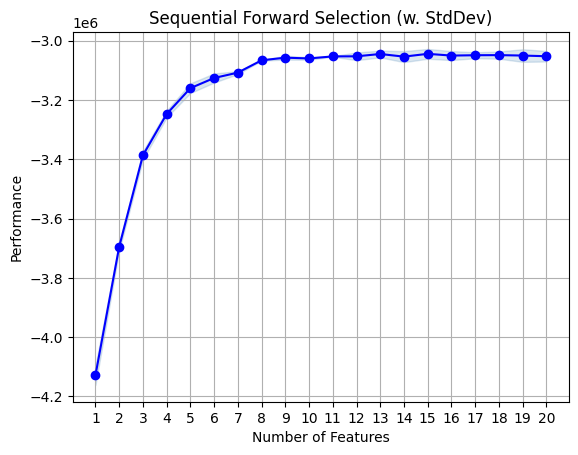

In [35]:
from xgboost import XGBRegressor
from mlxtend.feature_selection import SequentialFeatureSelector
from mlxtend.plotting import plot_sequential_feature_selection as plot_sfs
import matplotlib.pyplot as plt

model = XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=6, min_child_weight=1, subsample=0.8,
        colsample_bytree=0.8, objective="reg:squarederror", eval_metric="rmse", random_state=42, n_jobs=-1)

selection_model = XGBRegressor(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=4,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

sample_idx = X_train.sample(n=20_000,random_state=42,).index

X_sfs = X_train_transformed[X_train.index.get_indexer(sample_idx)]

y_sfs = y_train.loc[sample_idx]

sfs = SequentialFeatureSelector(selection_model,
    k_features=20,       
    forward=True,      
    floating=False,     
    scoring='neg_root_mean_squared_error', 
    cv=2,               
    n_jobs=-1)

sfs = sfs.fit(X_sfs, y_sfs)

fig1 = plot_sfs(sfs.get_metric_dict(), kind='std_dev')


plt.title('Sequential Forward Selection (w. StdDev)')
plt.grid()
plt.savefig("fs_assets/sfs_20.png")
plt.show() 

После 10 признаков наблюдается плато

In [36]:
selected_idx_sfs = np.array(sfs.k_feature_idx_)
feature_names = preprocessor.get_feature_names_out()
selected_names = feature_names[selected_idx_sfs]

print(selected_names)

['living_area' 'total_area' 'ceiling_height' 'building_type_int_4.0' 'id'
 'build_year' 'latitude' 'longitude' 'floors_total' 'has_elevator'
 '1/(floors_total*rooms)' 'kitchen_area/floors_total'
 'log(total_area)/ceiling_height' 'sqrt(flats_count)*floors_total'
 'kitchen_area*sqrt(living_area)' 'log(ceiling_height)*log(total_area)'
 'sqrt(flats_count)*sqrt(kitchen_area)' 'log(rooms)/flats_count'
 'living_area/rooms' 'distance_to_center']


Проверим на исходной модели

In [37]:
import time

X_train_selected = X_train_transformed[:, selected_idx_sfs]
X_test_selected = X_test_transformed[:, selected_idx_sfs]

start = time.perf_counter()
model.fit(X_train_selected, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = model.predict(X_test_selected)
predict_time = time.perf_counter() - start


metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    'train_time_sec': train_time,
    'predict_time_sec': predict_time
}

print(metrics)

{'rmse': 2593589.903888312, 'mae': 1809467.0971811612, 'r2': 0.8295166006255016, 'train_time_sec': 5.180529802997626, 'predict_time_sec': 0.21324468400052865}


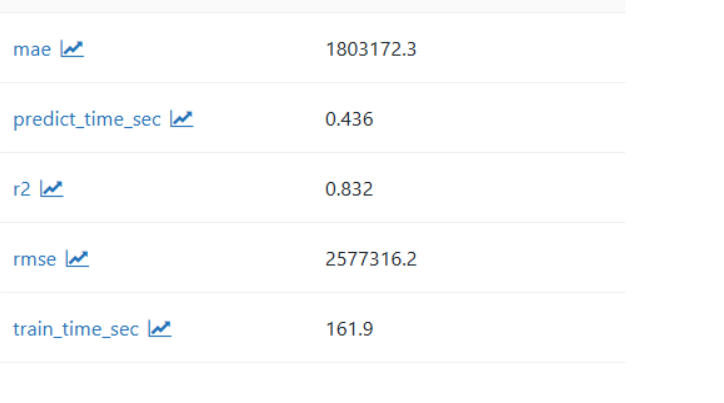 - Модель до отбора<br>
Можно увидеть, что показатели модели почти не изменились, но производительность улучшилась вдвое.. Среди отобранных признаков оказалось немало автоматически полученных с помощью библиотеки autofeat<br>
Залогируем результат

In [40]:
import numpy as np

#Конвертор в питон типы для удобного просмотра в mlflow веб интерфейсе
def convert_numpy(obj):
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    return obj

In [41]:
import mlflow
import json

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_registry_uri("http://127.0.0.1:5000")

experiment_id = mlflow.get_experiment_by_name("flats_price").experiment_id
with mlflow.start_run(experiment_id=experiment_id, run_name="feat_selection") as run:
    mlflow.log_artifact("fs_assets/sfs_20.png", artifact_path="artifacts")
    mlflow.log_metrics(metrics)
    metrics_dict = json.loads(json.dumps(sfs.get_metric_dict(), default=convert_numpy))

    mlflow.log_dict(metrics_dict, "feature_selection/sfs_metrics.json")
    mlflow.log_params(model.get_params())
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("selection_type", "sfs")
    mlflow.log_param("selected_features",", ".join(selected_names))

Проверим теперь при floating=True

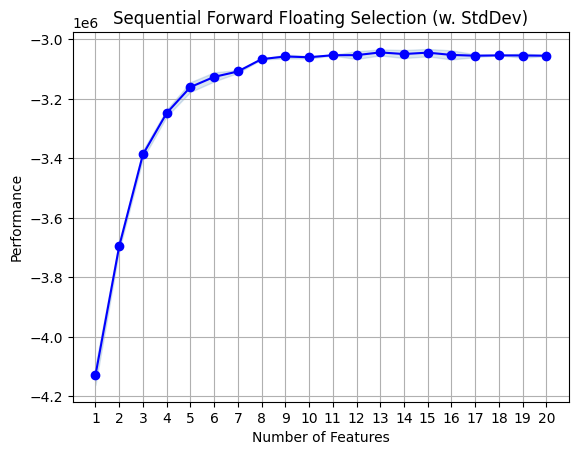

In [42]:
sffs = SequentialFeatureSelector(selection_model,
    k_features=20,       
    forward=True,      
    floating=True,     
    scoring='neg_root_mean_squared_error', 
    cv=2,               
    n_jobs=-1)

sffs = sffs.fit(X_sfs, y_sfs)

fig1 = plot_sfs(sffs.get_metric_dict(), kind='std_dev')


plt.title('Sequential Forward Floating Selection (w. StdDev)')
plt.grid()
plt.savefig("fs_assets/sffs_20.png")
plt.show() 

In [43]:
selected_idx_sffs = np.array(sffs.k_feature_idx_)
feature_names = preprocessor.get_feature_names_out()
selected_names = feature_names[selected_idx_sffs]

print(selected_names)

['total_area' 'ceiling_height' 'building_type_int_3.0'
 'building_type_int_4.0' 'id' 'build_year' 'latitude' 'longitude'
 'floors_total' '1/(floor*floors_total)' '1/(floors_total*rooms)'
 'living_area/total_area' 'flats_count/total_area'
 'kitchen_area*log(rooms)' 'kitchen_area/total_area'
 'log(ceiling_height)*log(total_area)' 'total_area/rooms'
 '1/sqrt(flats_count)' 'sqrt(living_area)/rooms' 'distance_to_center']


Смотрим показатели модели на отобранных признаках.

In [44]:
import time

X_train_selected = X_train_transformed[:, selected_idx_sffs]
X_test_selected = X_test_transformed[:, selected_idx_sffs]

start = time.perf_counter()
model.fit(X_train_selected, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = model.predict(X_test_selected)
predict_time = time.perf_counter() - start


metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    'train_time_sec': train_time,
    'predict_time_sec': predict_time
}

print(metrics)

{'rmse': 2570874.158523527, 'mae': 1797416.2860926336, 'r2': 0.832489852723805, 'train_time_sec': 5.07784516600077, 'predict_time_sec': 0.20976303400675533}


Логируем

In [45]:
import mlflow


experiment_id = mlflow.get_experiment_by_name("flats_price").experiment_id
with mlflow.start_run(experiment_id=experiment_id, run_name="feat_selection") as run:
    mlflow.log_artifact("fs_assets/sffs_20.png", artifact_path="artifacts")
    mlflow.log_metrics(metrics)
    metrics_dict = json.loads(json.dumps(sffs.get_metric_dict(), default=convert_numpy))
    
    mlflow.log_dict(metrics_dict, "feature_selection/sffs_metrics.json")
    mlflow.log_params(model.get_params())
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("selection_type", "sffs")
    mlflow.log_param("selected_features",", ".join(selected_names))

SFS и SFFS выбрали похожие, но не одинаковые наборы признаков. Оба метода сохранили  признаки площади и местоположения, включая distance_to_center, а также ряд признаков, созданных AutoFeat. После 8–10 признаков качество выходит на плато. Совсем немного лучше оказалась модель на признаках отобранных с помощью sffs.

Теперь объединим признаки и посмотрим на качество модели.

In [46]:
union_feat = list(set(selected_idx_sffs) | set(selected_idx_sfs))
feature_names = preprocessor.get_feature_names_out()
selected_names = feature_names[union_feat]
X_train_selected = X_train_transformed[:, union_feat]
X_test_selected = X_test_transformed[:, union_feat]

start = time.perf_counter()
model.fit(X_train_selected, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = model.predict(X_test_selected)
predict_time = time.perf_counter() - start


metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    'train_time_sec': train_time,
    'predict_time_sec': predict_time
}

print(metrics)

{'rmse': 2578349.902803467, 'mae': 1800251.6627864006, 'r2': 0.8315142439220455, 'train_time_sec': 6.746610207999765, 'predict_time_sec': 0.20652205499936827}


In [47]:
import mlflow


experiment_id = mlflow.get_experiment_by_name("flats_price").experiment_id
with mlflow.start_run(experiment_id=experiment_id, run_name="feat_selection") as run:
    mlflow.log_metrics(metrics)

    mlflow.log_params(model.get_params())
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("selection_type", "union sfs sffs")
    mlflow.log_dict({"selected_features": selected_names.tolist()}, "selected_features.json")

На объединённом наборе признаков модель не продемонстрировала существенного улучшения метрик, поэтому для дальнейшей работы была выбрана модель, обученная на признаках, отобранных методом SFFS.

Регистрируем

In [25]:
selected_idx_sffs = np.array(sffs.k_feature_idx_)

feature_names = preprocessor.get_feature_names_out()
selected_names = feature_names[selected_idx_sffs]

X_train_selected = X_train_transformed[:, selected_idx_sffs]
X_test_selected = X_test_transformed[:, selected_idx_sffs]

start = time.perf_counter()
model.fit(X_train_selected, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = model.predict(X_test_selected)
predict_time = time.perf_counter() - start
xgb_pipe = Pipeline([('preprocessor', preprocessor),
                    ('model', model)])
metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    "train_time_sec": train_time,
    "predict_time_sec": predict_time,
}

signature = mlflow.models.infer_signature(X_test_selected, pred)

input_example = X_test_selected[:10]

with mlflow.start_run(
    experiment_id=experiment_id,
    run_name="xgb_selection_model_registry"
) as run:

    mlflow.log_params(model.get_params())
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("train_size", 0.8)
    mlflow.log_param("model", "XGBoost")
    mlflow.log_param("selection_type", "SFFS")

    mlflow.log_metrics(metrics)

    mlflow.log_dict(
        {"selected_features": selected_names.tolist()},
        "selected_features.json"
    )

   
    mlflow.sklearn.log_model(sk_model=preprocessor, artifact_path="preprocessor", pip_requirements="../requirements.txt",)

   
    mlflow.xgboost.log_model(
        xgb_model=model,
        artifact_path="model",
        signature=signature,
        input_example=input_example,
        pip_requirements="../requirements.txt",
        registered_model_name="flats_price_model",
        await_registration_for=60,
    )

2026/08/19 13:38:05 WARNING mlflow.sklearn: Model was missing function: predict. Not logging python_function flavor!
/home/mle-user/mle_projects/mle-project-sprint-2-v001/venv/lib/python3.10/site-packages/xgboost/sklearn.py:1116: UserWarning: [13:38:05] WARNING: /__w/xgboost/xgboost/src/c_api/c_api.cc:1573: Saving model in the UBJSON format as default.  You can use a file extension: `json` or `ubj` to choose between formats.
  self.get_booster().save_model(fname)
Registered model 'flats_price_model' already exists. Creating a new version of this model...
2026/08/19 13:38:05 INFO mlflow.tracking._model_registry.client: Waiting up to 60 seconds for model version to finish creation. Model name: flats_price_model, version 3
Created version '3' of model 'flats_price_model'.


## Подбор гиперпараметров

Подбор гиперпараметров проведём с помощью библиотеки Optuna. Сравним два алгоритма поиска: TPESampler и RandomSampler. Будем оптимизировать основные гиперпараметры XGBoost: n_estimators, max_depth, learning_rate, min_child_weight, subsample и colsample_bytree. В качестве целевой метрики оптимизации используем RMSE.

In [26]:
X_train = X_train_selected
X_test = X_test_selected

from xgboost import XGBRegressor
import optuna
from optuna.integration.mlflow import MLflowCallback


EXPERIMENT_NAME = "flats_price"
RUN_NAME="hypeparams"
STUDY_DB_NAME = 'sqlite:///local.study.db'
STUDY_NAME = 'TPE'
TRACKING_SERVER_HOST = "localhost"
TRACKING_SERVER_PORT = 5000
def objective(trial):
    # Создаем валидационную выборку
    X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0)
    }
    model = XGBRegressor(**params, objective="reg:squarederror",  eval_metric="rmse", random_state=42, n_jobs=-1)
    model.fit(X_tr, y_tr)

    pred = model.predict(X_val)

    rmse = np.sqrt(mean_squared_error(y_val, pred))

    return rmse

experiment_id = mlflow.get_experiment_by_name(EXPERIMENT_NAME).experiment_id

with mlflow.start_run(run_name=RUN_NAME, experiment_id=experiment_id) as run:
    run_id = run.info.run_id

    mlflc = MLflowCallback(tracking_uri=f'http://{TRACKING_SERVER_HOST}:{TRACKING_SERVER_PORT}',
                           metric_name="rmse", create_experiment=False,
                           mlflow_kwargs={'experiment_id': experiment_id, 'tags': {'mlflow.parentRunId': run_id}})

study = optuna.create_study(direction='minimize', study_name=STUDY_NAME,
                                 storage=STUDY_DB_NAME, load_if_exists=True, sampler=optuna.samplers.TPESampler())
study.optimize(objective, n_trials=20, callbacks=[mlflc])
best_params = study.best_params

print(f"Number of finished trials: {len(study.trials)}")
print(f"Best params: {best_params}")

/tmp/ipykernel_24481/1297128871.py:40: ExperimentalWarning: MLflowCallback is experimental (supported from v1.4.0). The interface can change in the future.
  mlflc = MLflowCallback(tracking_uri=f'http://{TRACKING_SERVER_HOST}:{TRACKING_SERVER_PORT}',
[I 2026-08-19 13:42:27,888] A new study created in RDB with name: TPE
[I 2026-08-19 13:42:56,650] Trial 0 finished with value: 2509651.72900594 and parameters: {'n_estimators': 531, 'max_depth': 12, 'learning_rate': 0.027395755027653318, 'min_child_weight': 4, 'subsample': 0.6058099229501742, 'colsample_bytree': 0.7298763325486733}. Best is trial 0 with value: 2509651.72900594.
[I 2026-08-19 13:43:19,614] Trial 1 finished with value: 2477953.95215581 and parameters: {'n_estimators': 704, 'max_depth': 9, 'learning_rate': 0.05439036802709164, 'min_child_weight': 1, 'subsample': 0.8536950831136245, 'colsample_bytree': 0.8801485781897915}. Best is trial 1 with value: 2477953.95215581.
[I 2026-08-19 13:43:24,072] Trial 2 finished with value: 25

Number of finished trials: 20
Best params: {'n_estimators': 991, 'max_depth': 10, 'learning_rate': 0.03438245346140569, 'min_child_weight': 1, 'subsample': 0.7298301886728183, 'colsample_bytree': 0.8607039200621948}


In [27]:
study.best_value

2475395.291340097

In [28]:
fig = optuna.visualization.plot_param_importances(study)
fig.write_image("hp_assets/tpe_param_importances.png")
fig.show() 

Наиболее важными параметрами с заметным отрывом оказались max_depth, далее после него идут learning_rate и min_child_weight

In [29]:
fig = optuna.visualization.plot_timeline(study)
fig.write_image("hp_assets/tpe_timeline.png")
fig.show() 

/tmp/ipykernel_24481/110658789.py:1: ExperimentalWarning:

plot_timeline is experimental (supported from v3.2.0). The interface can change in the future.



Теперь проверим sampler RandomSampler.

In [30]:
RUN_NAME = 'RandomSampler'
STUDY_NAME = "RandomSampler"
def objective(trial):
    # Создаем валидационную выборку
    X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0)
    }
    model = XGBRegressor(**params, objective="reg:squarederror",  eval_metric="rmse", random_state=42, n_jobs=-1)
    model.fit(X_tr, y_tr)

    pred = model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, pred))

    return rmse

experiment_id = mlflow.get_experiment_by_name(EXPERIMENT_NAME).experiment_id

with mlflow.start_run(run_name=RUN_NAME, experiment_id=experiment_id) as run:
    run_id = run.info.run_id

    mlflc = MLflowCallback(tracking_uri=f'http://{TRACKING_SERVER_HOST}:{TRACKING_SERVER_PORT}',
                           metric_name="rmse", create_experiment=False,
                           mlflow_kwargs={'experiment_id': experiment_id, 'tags': {'mlflow.parentRunId': run_id}})
study_2 = optuna.create_study(direction='minimize', study_name=STUDY_NAME,
                                 storage=STUDY_DB_NAME, load_if_exists=True, sampler=optuna.samplers.RandomSampler(seed=42))
study_2.optimize(objective, n_trials=20, callbacks=[mlflc])
best_params = study_2.best_params

print(f"Best_value: {study_2.best_value}")
print(f"Best params: {best_params}")

/tmp/ipykernel_24481/2119003806.py:27: ExperimentalWarning:

MLflowCallback is experimental (supported from v1.4.0). The interface can change in the future.

[I 2026-08-19 13:50:56,487] A new study created in RDB with name: RandomSampler
[I 2026-08-19 13:51:18,552] Trial 0 finished with value: 2577064.269558633 and parameters: {'n_estimators': 437, 'max_depth': 12, 'learning_rate': 0.1205712628744377, 'min_child_weight': 6, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481}. Best is trial 0 with value: 2577064.269558633.
[I 2026-08-19 13:51:25,750] Trial 1 finished with value: 2559576.340963908 and parameters: {'n_estimators': 152, 'max_depth': 11, 'learning_rate': 0.07725378389307355, 'min_child_weight': 8, 'subsample': 0.608233797718321, 'colsample_bytree': 0.9879639408647978}. Best is trial 1 with value: 2559576.340963908.
[I 2026-08-19 13:51:32,683] Trial 2 finished with value: 2690275.637512181 and parameters: {'n_estimators': 850, 'max_depth': 5, 'learning_ra

Best_value: 2520815.070409665
Best params: {'n_estimators': 207, 'max_depth': 10, 'learning_rate': 0.13297554090738672, 'min_child_weight': 6, 'subsample': 0.9083868719818244, 'colsample_bytree': 0.7975182385457563}


In [31]:
fig = optuna.visualization.plot_param_importances(study_2)
fig.write_image("hp_assets/random_search_param_importances.png")
fig.show() 

In [32]:
fig = optuna.visualization.plot_timeline(study_2)
fig.write_image("hp_assets/random_search_timeline.png")
fig.show() 

/tmp/ipykernel_24481/396704118.py:1: ExperimentalWarning:

plot_timeline is experimental (supported from v3.2.0). The interface can change in the future.



По результатам экспериментов TPE показал себя лучше Random Search: подобранные им гиперпараметры обеспечили более высокое качество модели, хотя вторая модель оказалась производительнее.
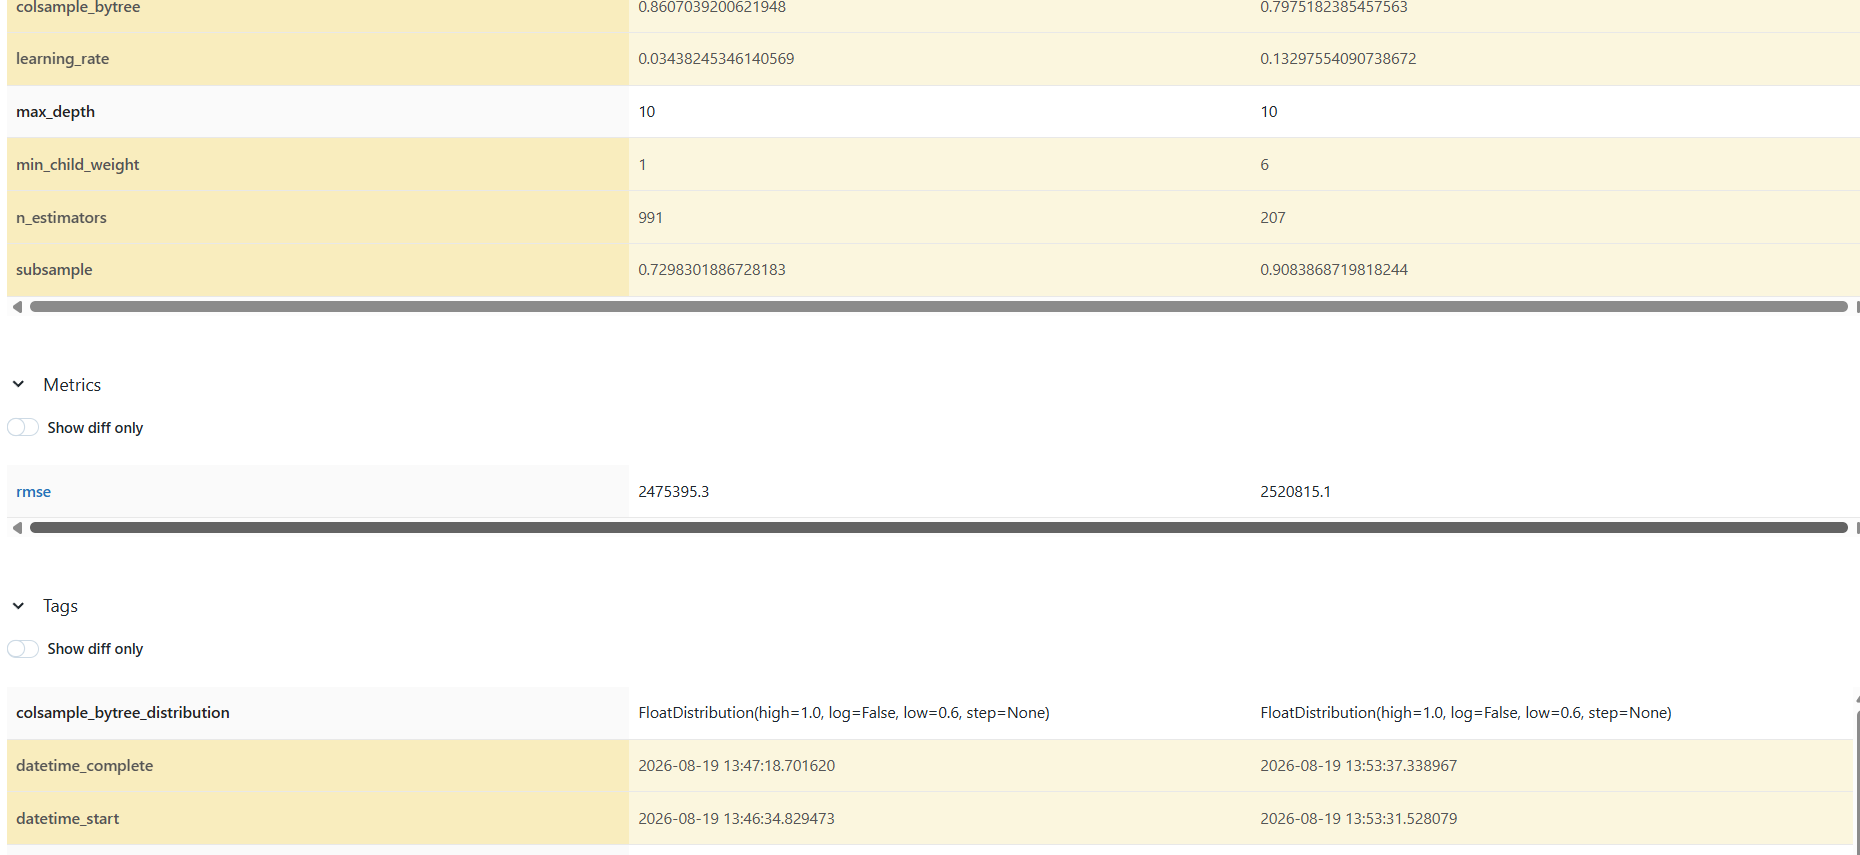
Для итоговой модели возьмём гиперпараметры, подобранные методом TPE.
Собираем все в один pipeline

Оборачиваем distance_to_center в transformer

In [2]:
from sklearn.base import BaseEstimator, TransformerMixin
import numpy as np


class DistanceToCenterTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, center_lat=55.7520, center_lon=37.6175):
        self.center_lat = center_lat
        self.center_lon = center_lon

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()

        R = 6371

        lat = np.radians(X["latitude"])
        lon = np.radians(X["longitude"])

        center_lat = np.radians(self.center_lat)
        center_lon = np.radians(self.center_lon)

        dlat = lat - center_lat
        dlon = lon - center_lon

        a = (
            np.sin(dlat / 2) ** 2
            + np.cos(center_lat)
            * np.cos(lat)
            * np.sin(dlon / 2) ** 2
        )

        X["distance_to_center"] = (
            2 * R * np.arcsin(np.sqrt(a))
        )

        return X

Оборачиваем признаки AutoFeat

In [21]:
from sklearn.base import BaseEstimator, TransformerMixin
import numpy as np


class AutoFeatFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        X["flats_count*floor"] = X["flats_count"] * X["floor"]
        X["1/(floors_total*rooms)"] = 1 / (X["floors_total"] * X["rooms"])
        X["sqrt(flats_count)*log(floor)"] = np.sqrt(X["flats_count"]) * np.log(X["floor"])
        X["kitchen_area*sqrt(living_area)"] = X["kitchen_area"] * np.sqrt(X["living_area"])
        X["sqrt(flats_count)*floors_total"] = np.sqrt(X["flats_count"]) * X["floors_total"]
        X["sqrt(kitchen_area)*sqrt(rooms)"] = np.sqrt(X["kitchen_area"]) * np.sqrt(X["rooms"])
        X["log(total_area)/ceiling_height"] = np.log(X["total_area"]) / X["ceiling_height"]
        X["log(ceiling_height)*log(total_area)"] = np.log(X["ceiling_height"]) * np.log(X["total_area"])
        X["floors_total/total_area"] = X["floors_total"] / X["total_area"]
        X["sqrt(living_area)/floors_total"] = np.sqrt(X["living_area"]) / X["floors_total"]
        X["log(flats_count)/ceiling_height"] = np.log(X["flats_count"]) / X["ceiling_height"]

        return X

Transformer для выбранных признаков

In [22]:
class FeatureSelector(BaseEstimator, TransformerMixin):
    def __init__(self, features):
        self.features = features

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.loc[:, self.features]

Robust и OneHot преобразования

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler


rob_feat = [
    "kitchen_area",
    "living_area",
    "total_area",
    "ceiling_height",
]

cat_features = [
    "building_type_int", "has_elevator", 'is_apartment'
]

preprocessor = ColumnTransformer(
    transformers=[
        ("robust_scaler", RobustScaler(quantile_range=(10, 90)), rob_feat),
        ("categorical", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), cat_features)
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

preprocessor.set_output(transform="pandas")

ColumnTransformer(remainder='passthrough',
                  transformers=[('robust_scaler',
                                 RobustScaler(quantile_range=(10, 90)),
                                 ['kitchen_area', 'living_area', 'total_area',
                                  'ceiling_height']),
                                ('categorical',
                                 OneHotEncoder(drop='if_binary',
                                               handle_unknown='ignore',
                                               sparse_output=False),
                                 ['building_type_int', 'has_elevator',
                                  'is_apartment'])],
                  verbose_feature_names_out=False)

Итоговый pipeline

In [24]:
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor

selected_features = [
    "total_area",
    "building_type_int_2",
    "id",
    "rooms",
    "build_year",
    "latitude",
    "longitude",
    "floors_total",
    "flats_count*floor",
    "1/(floors_total*rooms)",
    "sqrt(flats_count)*log(floor)",
    "kitchen_area*sqrt(living_area)",
    "sqrt(flats_count)*floors_total",
    "sqrt(kitchen_area)*sqrt(rooms)",
    "log(total_area)/ceiling_height",
    "log(ceiling_height)*log(total_area)",
    "floors_total/total_area",
    "sqrt(living_area)/floors_total",
    "log(flats_count)/ceiling_height",
    "distance_to_center",
]

best_params = {'n_estimators': 991,
               'max_depth': 10,
               'learning_rate': 0.03438245346140569,
                'min_child_weight': 1,
                'subsample': 0.7298301886728183,
                'colsample_bytree': 0.8607039200621948}

autofeat_cols = [
    "total_area",
    "living_area",
    "kitchen_area",
    "rooms",
    "floor",
    "floors_total",
    "flats_count",
    "ceiling_height",
]
transformations = ["1/", "log",  "sqrt"]

final_pipeline = Pipeline([
    ("autofeat", AutoFeatFeatures()),
    ("distance", DistanceToCenterTransformer()),
    ("preprocessor", preprocessor),
    ("feature_selector", FeatureSelector(selected_features)),
    ("model", XGBRegressor(**best_params, objective="reg:squarederror", eval_metric="rmse", random_state=42, n_jobs=2))
    ])


In [25]:
X_tmp = AutoFeatFeatures().fit_transform(X_train)
print(X_tmp.columns.tolist())
X_tmp = preprocessor.fit_transform(X_tmp)

print(X_tmp.columns.tolist())

['id', 'floor', 'kitchen_area', 'living_area', 'rooms', 'is_apartment', 'total_area', 'build_year', 'building_type_int', 'latitude', 'longitude', 'ceiling_height', 'flats_count', 'floors_total', 'has_elevator', 'flats_count*floor', '1/(floors_total*rooms)', 'sqrt(flats_count)*log(floor)', 'kitchen_area*sqrt(living_area)', 'sqrt(flats_count)*floors_total', 'sqrt(kitchen_area)*sqrt(rooms)', 'log(total_area)/ceiling_height', 'log(ceiling_height)*log(total_area)', 'floors_total/total_area', 'sqrt(living_area)/floors_total', 'log(flats_count)/ceiling_height']
['kitchen_area', 'living_area', 'total_area', 'ceiling_height', 'building_type_int_0', 'building_type_int_1', 'building_type_int_2', 'building_type_int_3', 'building_type_int_4', 'building_type_int_5', 'building_type_int_6', 'has_elevator_True', 'is_apartment_True', 'id', 'floor', 'rooms', 'build_year', 'latitude', 'longitude', 'flats_count', 'floors_total', 'flats_count*floor', '1/(floors_total*rooms)', 'sqrt(flats_count)*log(floor)',

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time
X = df.drop(columns = ['price', 'building_id', 'studio'])
y = df['price']


X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, shuffle=True, random_state=42)
start = time.perf_counter()
final_pipeline.fit(X_train, y_train)
train_time = time.perf_counter() - start

start = time.perf_counter()
pred = final_pipeline.predict(X_test)
predict_time = time.perf_counter() - start

metrics = {
    "rmse": mean_squared_error(y_test, pred, squared=False),
    "mae": mean_absolute_error(y_test, pred),
    "r2": r2_score(y_test, pred),
    'train_time_sec': train_time,
    'predict_time_sec': predict_time
}

In [27]:
metrics

{'rmse': 2440199.615830043,
 'mae': 1677634.797004599,
 'r2': 0.8490857702576617,
 'train_time_sec': 45.000205708001886,
 'predict_time_sec': 0.8386725960008334}

In [35]:
import mlflow
signature = mlflow.models.infer_signature(X_test, pred)

input_example = X_test[:10]
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_registry_uri("http://127.0.0.1:5000")

experiment_id = mlflow.get_experiment_by_name("flats_price").experiment_id
with mlflow.start_run(experiment_id=experiment_id, run_name="xgb_final_model") as run:

    mlflow.log_params(best_params)
    mlflow.log_param("seed", 42)
    mlflow.log_param("shuffle", True)
    mlflow.log_param("train_size", 0.8)
    mlflow.log_param("model", "XGBoost")

    mlflow.log_metrics(metrics)

    mlflow.log_dict(
        {"selected_features": selected_features},
        "selected_features.json"
    )

    mlflow.log_artifacts("hp_assets")
    mlflow.sklearn.log_model(
        sk_model=final_pipeline,
        artifact_path="model",
        signature=signature,
        input_example=input_example,
        pip_requirements="../requirements.txt",
        registered_model_name="flats_price_model",
        await_registration_for=60,
    )

/home/mle-user/mle_projects/mle-project-sprint-2-v001/venv/lib/python3.10/site-packages/mlflow/models/signature.py:212: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  inputs = _infer_schema(model_input) if model_input is not None else None
Registered model 'flats_price_model' already exists. Creating a new version of this model...
2026/08/19 14:40:11 INFO mlflow.tracking._mo

Теперь сравним полученные модели
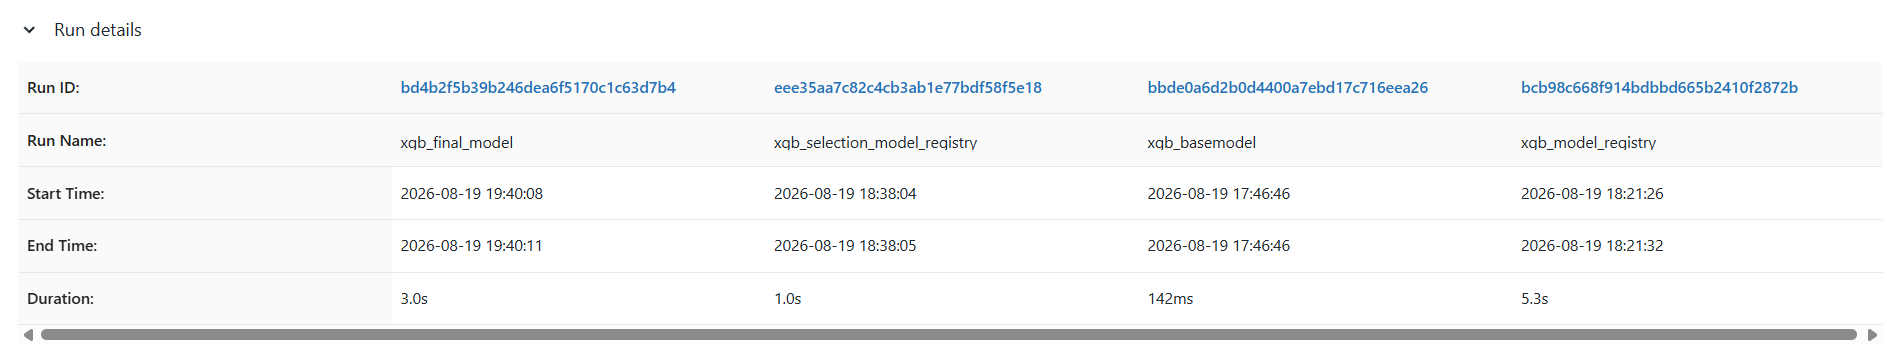
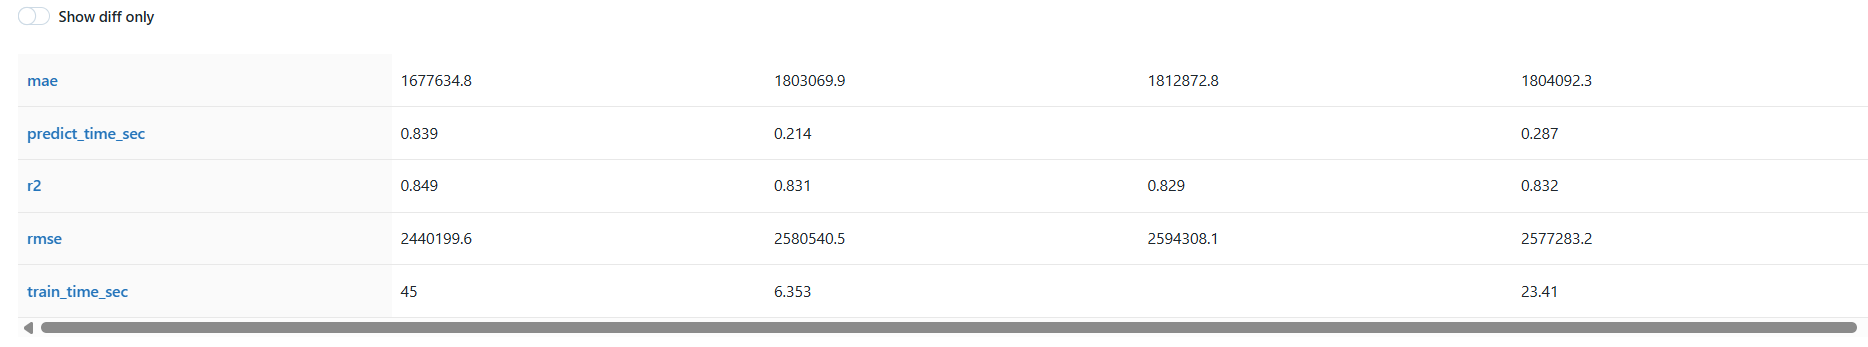

Сравнение моделей показывает, что финальная версия XGBoost продемонстрировала наилучшее качество. После создания новых признаков, отбора наиболее значимых из них и подбора гиперпараметров удалось снизить RMSE с 2.59 млн у базовой модели до 2.44 млн, а MAE — с 1.81 млн до 1.68 млн. При этом R² увеличился с 0.829 до 0.849. При этом улучшение качества сопровождалось увеличением времени обучения до 45 секунд и времени предсказания до 0.84 секунды, что связано с усложнением пайплайна и использованием дополнительных признаков.